<a href="https://colab.research.google.com/github/Mufliha-Hafsyah/PCVK_Ganjil_2026/blob/main/Week09/Week9_14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **LAPORAN PRAKTIKUM <br> Pengolahan Citra dan Visi Komputer (PCVK)**

**Nama** : Mufliha Hafsyah Shahieza <br>
**NIM** : 244107020147 <br>
**Kelas** : TI-3G

---

## **MODUL 9 – Morfologi (Erosi, Dilasi, Opening, Closing,Transformasi Top-hat dan Black-hat, Skeleton, Thinning, Thickening)**

<hr>

### **D. PRAKTIKUM MORFOLOGI**

1. **Akses file yang terdapat pada drive dan import beberapa library yang dibutuhkan**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


2. **Import beberapa library berikut yang akan digunakan selama uji coba praktikum
minggu ke-9 berikut.**

In [2]:
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

In [3]:
# Daftar citra yang diproses di setiap langkah morfologi
nama_citra = ['Noisy Text', 'Plat Nomor']
file_citra = ['/content/drive/MyDrive/PCVK2026/noisy_text.png',
              '/content/drive/MyDrive/PCVK2026/plat_nomor.png']
inv_citra  = [False, True]   # True -> THRESH_BINARY_INV

def load_biner(filename, thresh=127, maxval=255, inv=False):
    img_gray = cv.imread(filename, 0)
    if img_gray is None:
        raise FileNotFoundError(f'Gambar tidak terbaca, cek path: {filename}')
    mode = cv.THRESH_BINARY_INV if inv else cv.THRESH_BINARY
    _, binary = cv.threshold(img_gray, thresh, maxval, mode)
    return img_gray, binary

In [4]:
def dilasi_citra(F, SE):
    SE = np.asarray(SE, dtype=np.uint8)
    aktif = SE == 1
    h, w = SE.shape
    ph, pw = h // 2, w // 2
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    for i in range(ph, p - ph):
        for j in range(pw, q - pw):
            temp = F[i-ph:i+ph+1, j-pw:j+pw+1]
            imgD[i, j] = np.max(temp[aktif])      # maksimum hanya di posisi SE bernilai 1
    return imgD

def erosi_citra(F, SE):
    SE = np.asarray(SE, dtype=np.uint8)
    aktif = SE == 1
    h, w = SE.shape
    ph, pw = h // 2, w // 2
    m, n = F.shape
    imgE = np.zeros((m, n), dtype=np.uint8)
    for i in range(ph, m - ph):
        for j in range(pw, n - pw):
            temp = F[i-ph:i+ph+1, j-pw:j+pw+1]
            imgE[i, j] = np.min(temp[aktif])      # minimum hanya di posisi SE bernilai 1
    return imgE

def tampil(baris, judul_kolom, judul_figure=''):
    n_baris, n_kolom = len(baris), len(judul_kolom)
    plt.figure(figsize=(4 * n_kolom, 3 * n_baris))
    for r, (nama, row) in enumerate(zip(nama_citra, baris)):
        for c, gambar in enumerate(row):
            ax = plt.subplot(n_baris, n_kolom, r * n_kolom + c + 1)
            ax.imshow(gambar, cmap='gray')
            if r == 0: ax.set_title(judul_kolom[c])
            if c == 0: ax.set_ylabel(nama)
            ax.set_xticks([]); ax.set_yticks([])
    plt.suptitle(judul_figure)
    plt.tight_layout()
    plt.show()

## Langkah 3 - Dilasi tanpa library (SED Cross 3x3)

[[0 1 0]
 [1 1 1]
 [0 1 0]]
Noisy Text | piksel putih sebelum: 18617 | sesudah: 28834
Plat Nomor | piksel putih sebelum: 240989 | sesudah: 244128


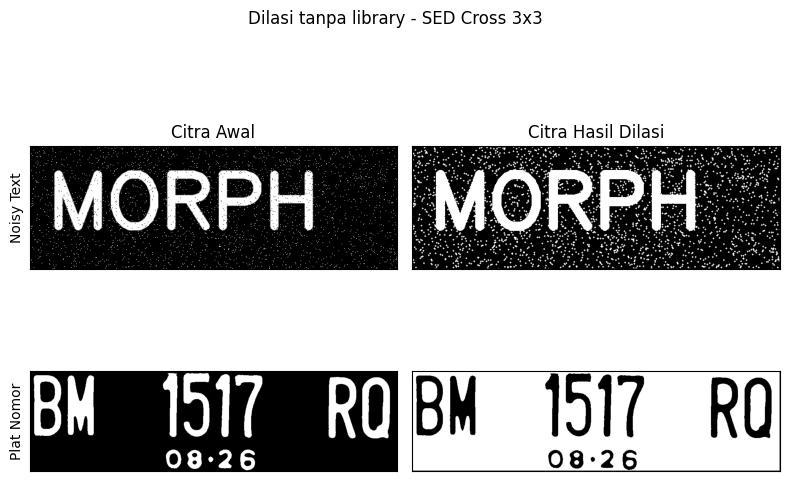

In [5]:
SED = cv.getStructuringElement(cv.MORPH_CROSS, (3, 3))
print(SED)

baris = []
for nama, file, inv in zip(nama_citra, file_citra, inv_citra):
    img, biner = load_biner(file, inv=inv)
    imgD = dilasi_citra(biner, SED)
    print(nama, '| piksel putih sebelum:', np.count_nonzero(biner), '| sesudah:', np.count_nonzero(imgD))
    baris.append([img, imgD])

tampil(baris, ['Citra Awal', 'Citra Hasil Dilasi'], 'Dilasi tanpa library - SED Cross 3x3')

## Langkah 4 - Dilasi dengan library OpenCV (Cross 3x3)

[[0 1 0]
 [1 1 1]
 [0 1 0]]
Noisy Text -> sama dengan versi manual? True
Plat Nomor -> sama dengan versi manual? True


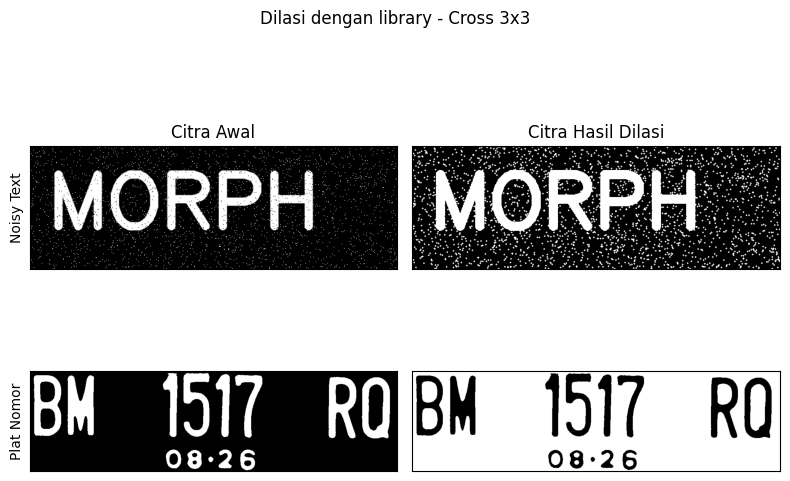

In [6]:
kernel = cv.getStructuringElement(cv.MORPH_CROSS, (3, 3))
print(kernel)

baris = []
for nama, file, inv in zip(nama_citra, file_citra, inv_citra):
    img, biner = load_biner(file, inv=inv)
    dilasi = cv.dilate(biner, kernel, iterations=1)
    manual = dilasi_citra(biner, kernel)
    # tepi 1 piksel tidak dibandingkan (loop manual tidak memprosesnya)
    print(nama, '-> sama dengan versi manual?', np.array_equal(dilasi[1:-1, 1:-1], manual[1:-1, 1:-1]))
    baris.append([img, dilasi])

tampil(baris, ['Citra Awal', 'Citra Hasil Dilasi'], 'Dilasi dengan library - Cross 3x3')

## Langkah 5 - Erosi tanpa library (SE Square 5x5)

Noisy Text | piksel putih sebelum: 18617 | sesudah: 6876
Plat Nomor | piksel putih sebelum: 240989 | sesudah: 221310


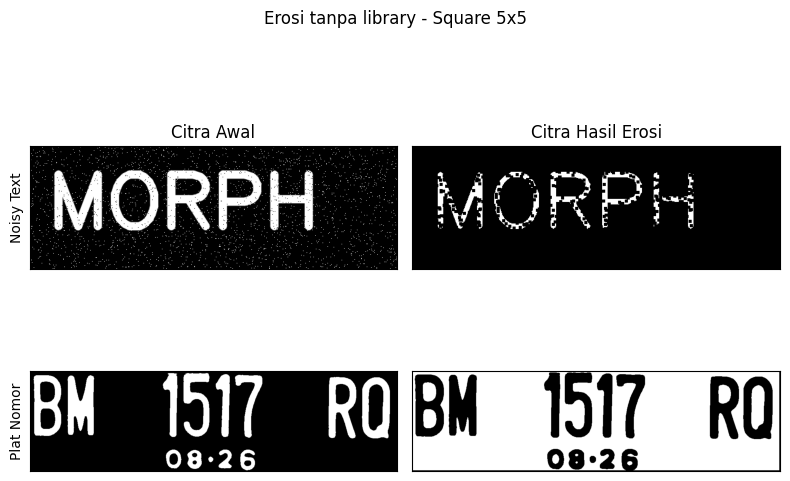

In [7]:
SE = np.ones((5, 5), dtype=np.uint8)

baris = []
for nama, file, inv in zip(nama_citra, file_citra, inv_citra):
    img, biner = load_biner(file, inv=inv)
    imgE = erosi_citra(biner, SE)
    print(nama, '| piksel putih sebelum:', np.count_nonzero(biner), '| sesudah:', np.count_nonzero(imgE))
    baris.append([img, imgE])

tampil(baris, ['Citra Awal', 'Citra Hasil Erosi'], 'Erosi tanpa library - Square 5x5')

## Langkah 6 - Erosi dengan library OpenCV (Square 5x5)

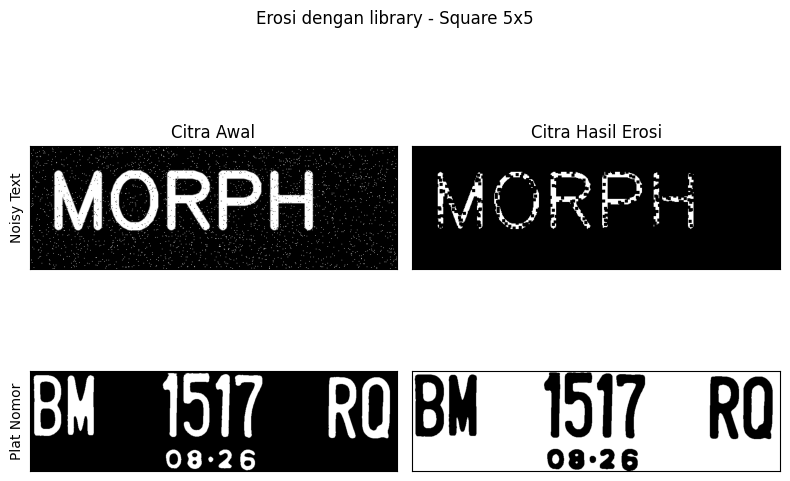

In [8]:
kernel = np.ones((5, 5), np.uint8)

baris = []
for nama, file, inv in zip(nama_citra, file_citra, inv_citra):
    img, biner = load_biner(file, inv=inv)
    erosion = cv.erode(biner, kernel, iterations=1)
    baris.append([img, erosion])

tampil(baris, ['Citra Awal', 'Citra Hasil Erosi'], 'Erosi dengan library - Square 5x5')

## Langkah 7 - Opening (Square 3x3), tanpa dan dengan library
Opening = erosi lalu dilasi.

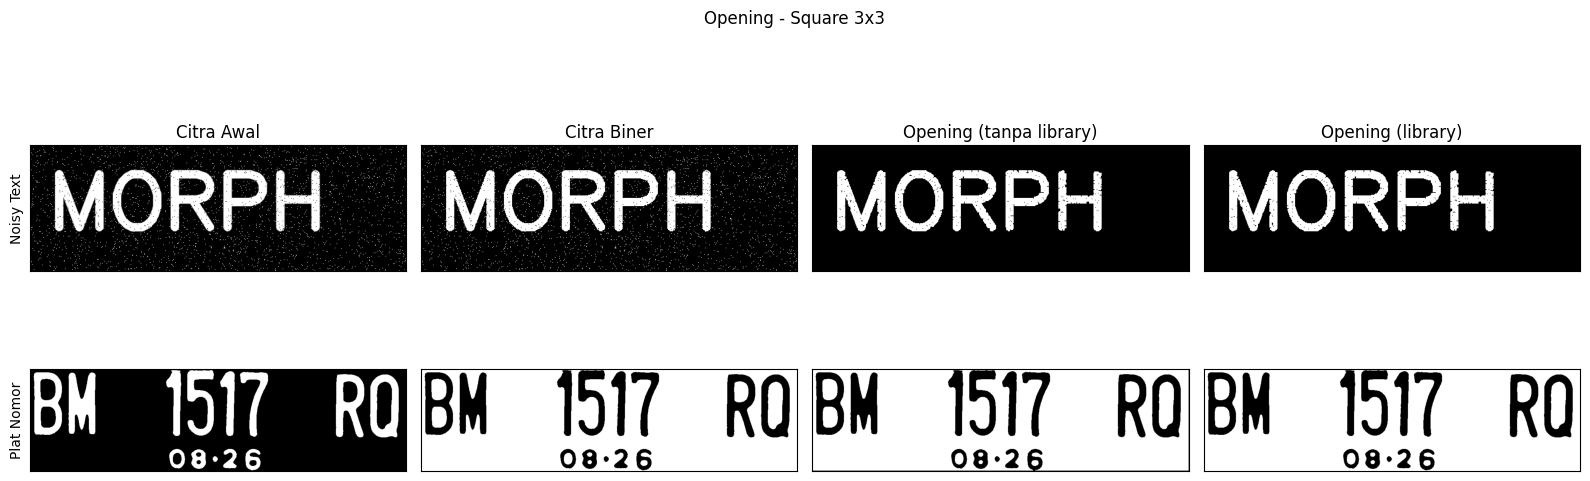

In [9]:
kernel = np.ones((3, 3), np.uint8)

baris = []
for nama, file, inv in zip(nama_citra, file_citra, inv_citra):
    img, biner = load_biner(file, inv=inv)
    open_manual  = dilasi_citra(erosi_citra(biner, kernel), kernel)
    open_library = cv.morphologyEx(biner, cv.MORPH_OPEN, kernel)
    baris.append([img, biner, open_manual, open_library])

tampil(baris, ['Citra Awal', 'Citra Biner', 'Opening (tanpa library)', 'Opening (library)'],
       'Opening - Square 3x3')

## Langkah 8 - Closing (Square 3x3), tanpa dan dengan library
Closing = dilasi lalu erosi.

In [11]:
import os
folder = '/content/drive/MyDrive/PCVK2026/'
print(os.listdir(folder))
print(os.path.exists(folder + 'plat_nomor.png'))

['galaxy.jpg', 'OBJ1.jpg', 'NIGHT1.jpg', 'ktm.jpeg', 'KTP1a.jpeg', 'KTP1b.jpeg', 'KTP1c.jpeg', 'KTP1d.jpeg', 'noises', 'lena.jpg', 'lena_lc.jpg', 'mandrill.tiff', 'djawatan.jpg', 'sudoku-original.jpg', 'lily.jpg', 'ktp_fulani.jpg', 'ktp_fulan.jpg', 'jungle.png', 'gradient.jpg', 'lena_gs_lc2.jpg', 'ktp_nayaz.jpeg', 'ktp_hafsya.jpeg', 'ktp_abid.jpg', 'ktp_fadhil.jpg', 'ktp_fattah.jpg', 'Plat_nomor_BM.png', 'noisy_text.png', 'kitten01 (1).jpg', 'ImageBiner', 'plat_nomor.png']
True


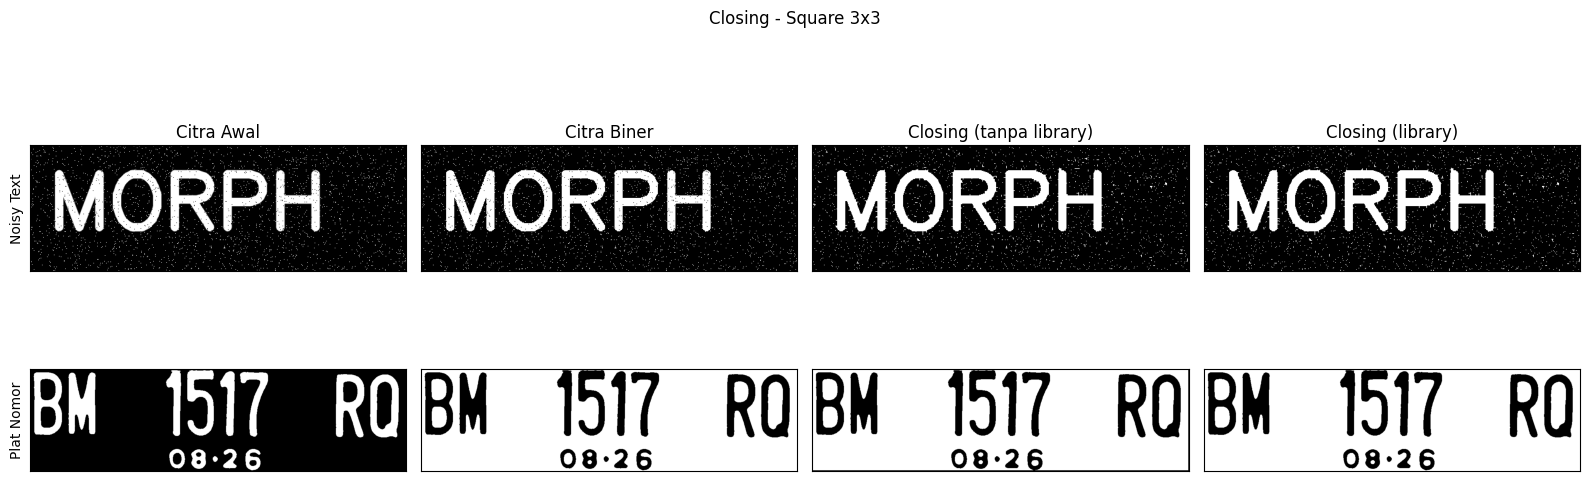

In [12]:
kernel = np.ones((3, 3), np.uint8)

baris = []
for nama, file, inv in zip(nama_citra, file_citra, inv_citra):
    img, biner = load_biner(file, inv=inv)
    close_manual  = erosi_citra(dilasi_citra(biner, kernel), kernel)
    close_library = cv.morphologyEx(biner, cv.MORPH_CLOSE, kernel)
    baris.append([img, biner, close_manual, close_library])

tampil(baris, ['Citra Awal', 'Citra Biner', 'Closing (tanpa library)', 'Closing (library)'],
       'Closing - Square 3x3')

## Langkah 9 - Dilasi SED Cross 3x3 dan 5x5

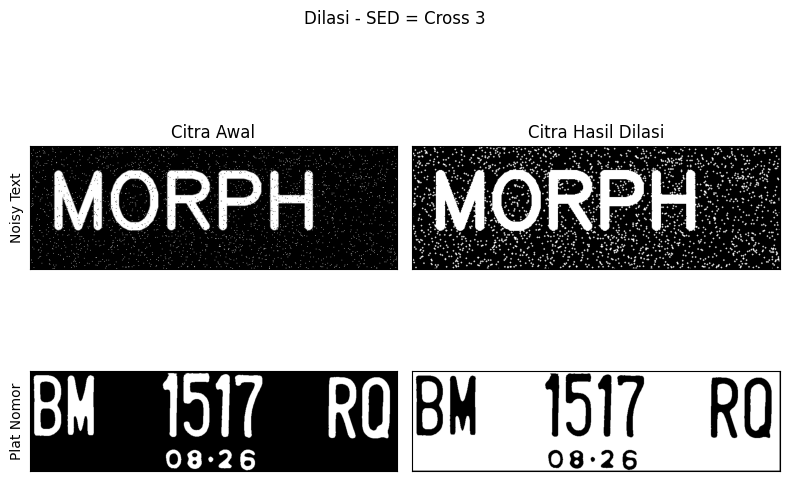

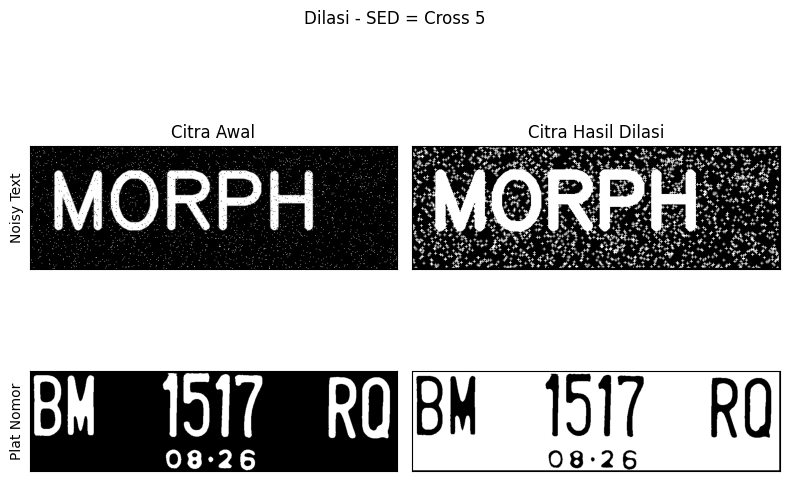

In [13]:
for w in [3, 5]:
    SED = cv.getStructuringElement(cv.MORPH_CROSS, (w, w))
    baris = []
    for nama, file, inv in zip(nama_citra, file_citra, inv_citra):
        img, biner = load_biner(file, inv=inv)
        baris.append([img, dilasi_citra(biner, SED)])
    tampil(baris, ['Citra Awal', 'Citra Hasil Dilasi'], f'Dilasi - SED = Cross {w}')

## Langkah 10 - Dilasi SED Circular 3x3 dan 5x5

Circle 3:
[[0 1 0]
 [1 1 1]
 [0 1 0]]


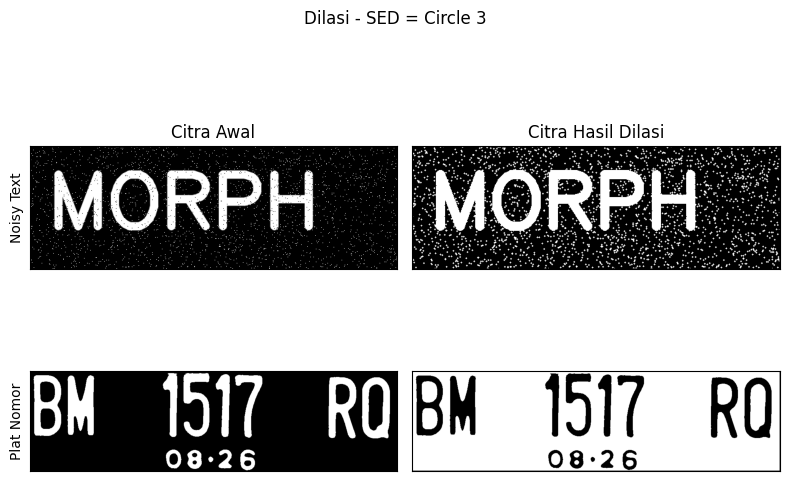

Circle 5:
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


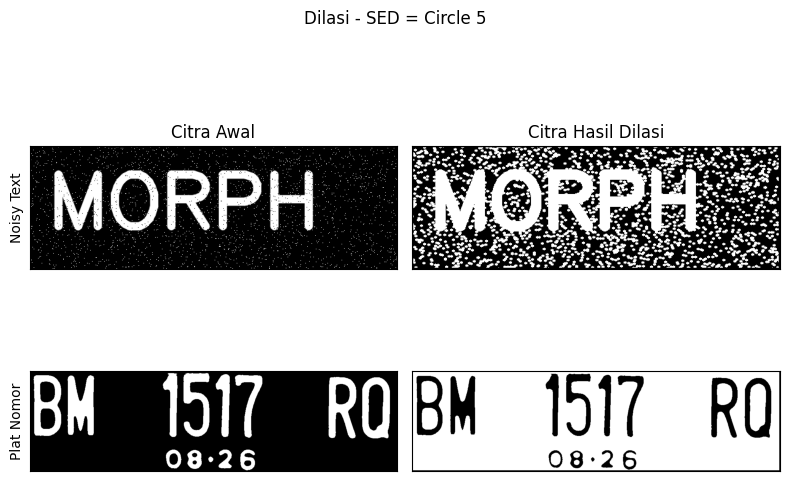

In [14]:
for w in [3, 5]:
    SED = cv.getStructuringElement(cv.MORPH_ELLIPSE, (w, w))
    print(f'Circle {w}:\n{SED}')
    baris = []
    for nama, file, inv in zip(nama_citra, file_citra, inv_citra):
        img, biner = load_biner(file, inv=inv)
        baris.append([img, dilasi_citra(biner, SED)])
    tampil(baris, ['Citra Awal', 'Citra Hasil Dilasi'], f'Dilasi - SED = Circle {w}')

## Langkah 11 - Erosi SE Rectangle 3x5 dan 5x7

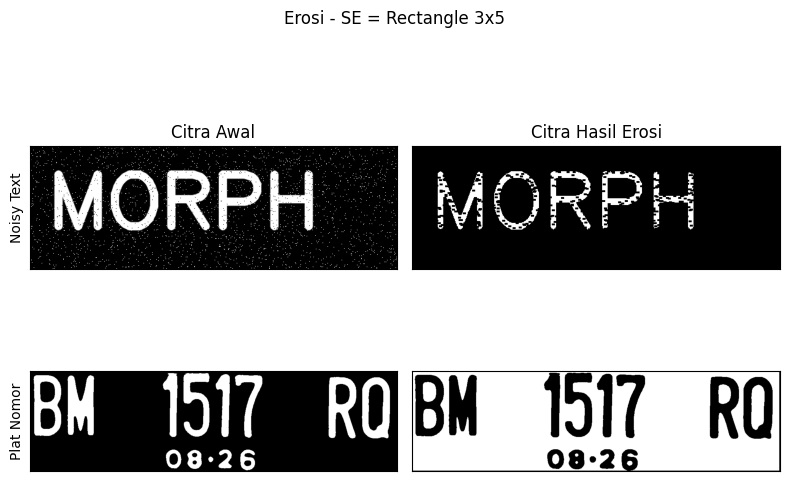

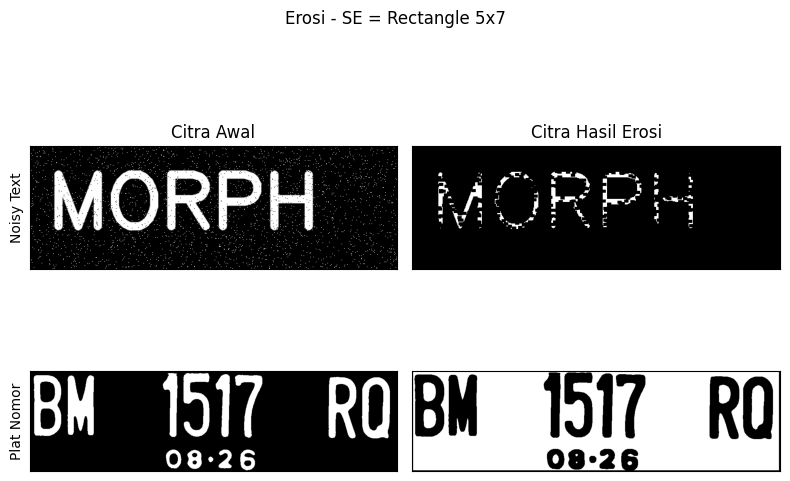

In [16]:
for lebar, tinggi in [(5, 3), (7, 5)]:
    SE = cv.getStructuringElement(cv.MORPH_RECT, (lebar, tinggi))
    baris = []
    for nama, file, inv in zip(nama_citra, file_citra, inv_citra):
        img, biner = load_biner(file, inv=inv)
        baris.append([img, erosi_citra(biner, SE)])
    tampil(baris, ['Citra Awal', 'Citra Hasil Erosi'], f'Erosi - SE = Rectangle {tinggi}x{lebar}')

## Langkah 12 - Erosi SE Line Vertikal 3 dan 5

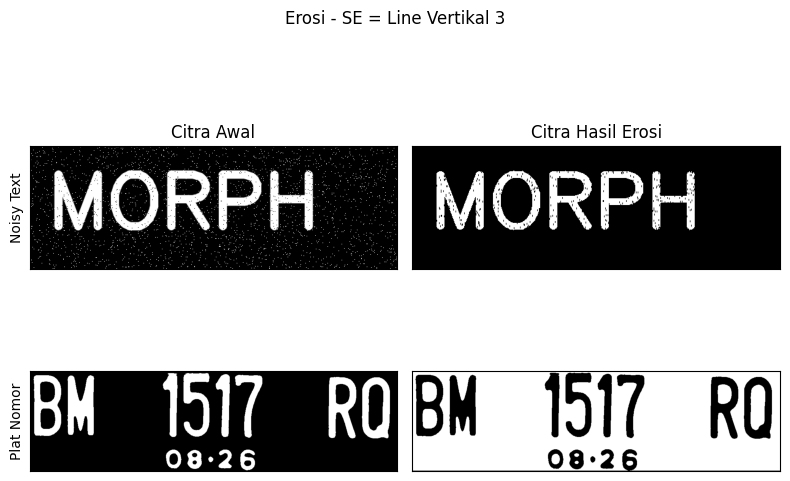

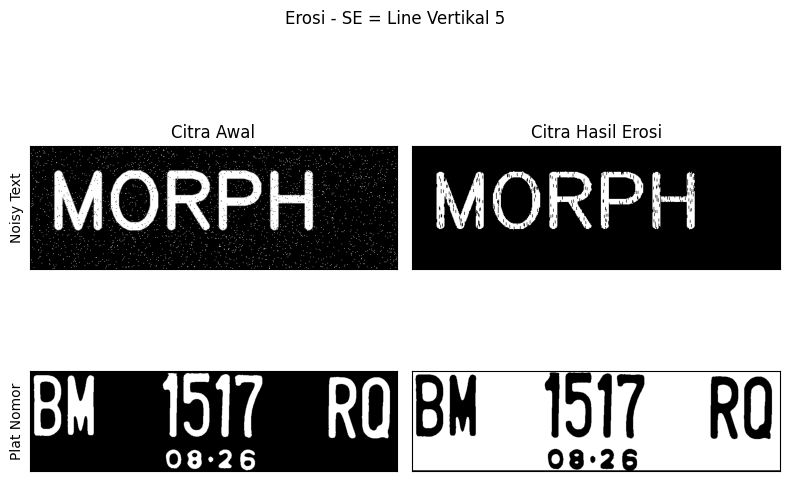

In [17]:
for k in [3, 5]:
    SE = np.ones((k, 1), dtype=np.uint8)     # garis vertikal: k baris, 1 kolom
    baris = []
    for nama, file, inv in zip(nama_citra, file_citra, inv_citra):
        img, biner = load_biner(file, inv=inv)
        baris.append([img, erosi_citra(biner, SE)])
    tampil(baris, ['Citra Awal', 'Citra Hasil Erosi'], f'Erosi - SE = Line Vertikal {k}')

sama dengan f - opening? True


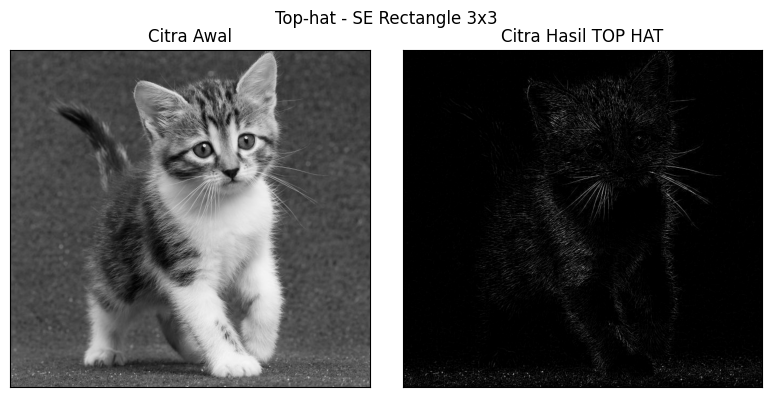

In [31]:
# Langkah 13 - Transformasi Top-hat (SE 3x3) pada citra kucing

# Fungsi bantu untuk menampilkan 2 citra berdampingan
def tampil_dua(a, b, judul_a, judul_b, judul=''):
    plt.figure(figsize=(8, 4))
    plt.subplot(121), plt.imshow(a, cmap='gray')
    plt.title(judul_a), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(b, cmap='gray')
    plt.title(judul_b), plt.xticks([]), plt.yticks([])
    plt.suptitle(judul)
    plt.tight_layout()
    plt.show()

# Structuring element 3x3
filterSize = (3, 3)
kernel = cv.getStructuringElement(cv.MORPH_RECT, filterSize)

# Baca citra kucing, langsung sebagai grayscale
path = '/content/drive/MyDrive/PCVK2026/kitten01.jpg'   # sesuaikan nama/path file
img = cv.imread(path, 0)
if img is None:
    raise FileNotFoundError(f'Gambar tidak terbaca, cek path: {path}')

# Operasi Top-hat
tophat_img = cv.morphologyEx(img, cv.MORPH_TOPHAT, kernel)

# Verifikasi rumus: top-hat = citra asli - opening
opening = cv.morphologyEx(img, cv.MORPH_OPEN, kernel)
print('sama dengan f - opening?', np.array_equal(tophat_img, cv.subtract(img, opening)))

# Tampilkan citra asal dan hasilnya berdampingan
tampil_dua(img, tophat_img, 'Citra Awal', 'Citra Hasil TOP HAT', 'Top-hat - SE Rectangle 3x3')

sama dengan closing - f? True


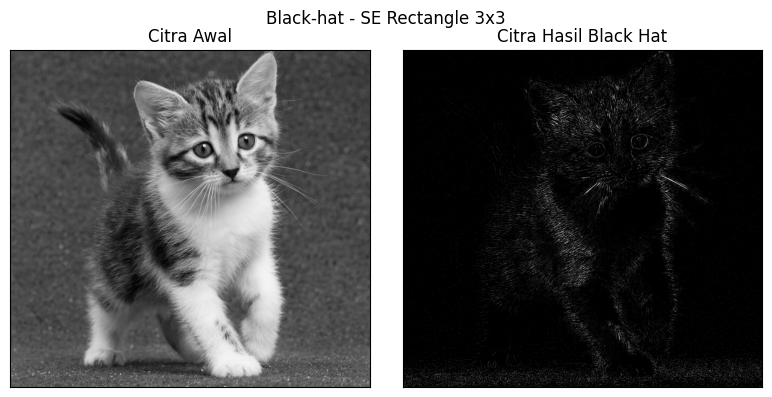

In [27]:
# Langkah 14 - Black-hat (SE 3x3)
path = '/content/drive/MyDrive/PCVK2026/kitten01.jpg'   # sesuaikan
img = cv.imread(path, 0)
if img is None:
    raise FileNotFoundError(f'Gambar tidak terbaca, cek path: {path}')

kernel = cv.getStructuringElement(cv.MORPH_RECT, (3, 3))
blackhat = cv.morphologyEx(img, cv.MORPH_BLACKHAT, kernel)

# verifikasi rumus: black-hat = closing - citra asli
closing = cv.morphologyEx(img, cv.MORPH_CLOSE, kernel)
print('sama dengan closing - f?', np.array_equal(blackhat, cv.subtract(closing, img)))

tampil_dua(img, blackhat, 'Citra Awal', 'Citra Hasil Black Hat', 'Black-hat - SE Rectangle 3x3')

threshold: 253 | piksel True: 212716 | piksel skeleton: 15477


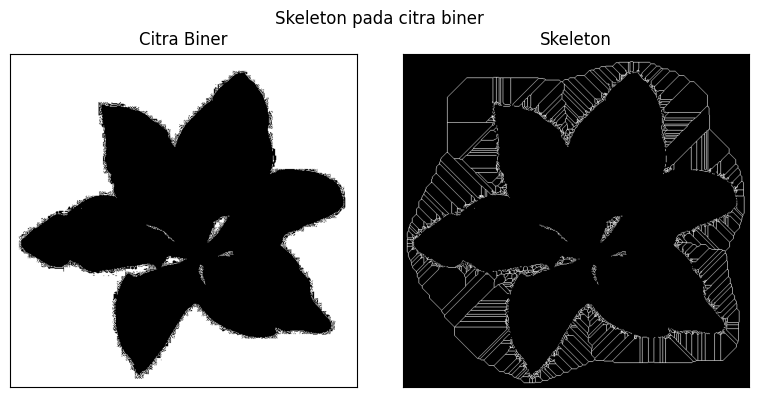

In [28]:
# Langkah 15 - Skeleton pada citra biner
from skimage import filters
from skimage.morphology import skeletonize

path = '/content/drive/MyDrive/PCVK2026/lily.jpg'   # sesuaikan
img = cv.imread(path, 0)
if img is None:
    raise FileNotFoundError(f'Gambar tidak terbaca, cek path: {path}')

# threshold otomatis (segitiga); img > t -> bagian TERANG jadi True
t = filters.threshold_triangle(img)
binary = img > t

skeleton = skeletonize(binary)
print('threshold:', t, '| piksel True:', np.count_nonzero(binary),
      '| piksel skeleton:', np.count_nonzero(skeleton))

tampil_dua(binary, skeleton, 'Citra Biner', 'Skeleton', 'Skeleton pada citra biner')

threshold: 253
Langkah 15 -> piksel True: 212716 | piksel skeleton: 15477
Langkah 16 -> piksel True: 158865 | piksel skeleton: 18916


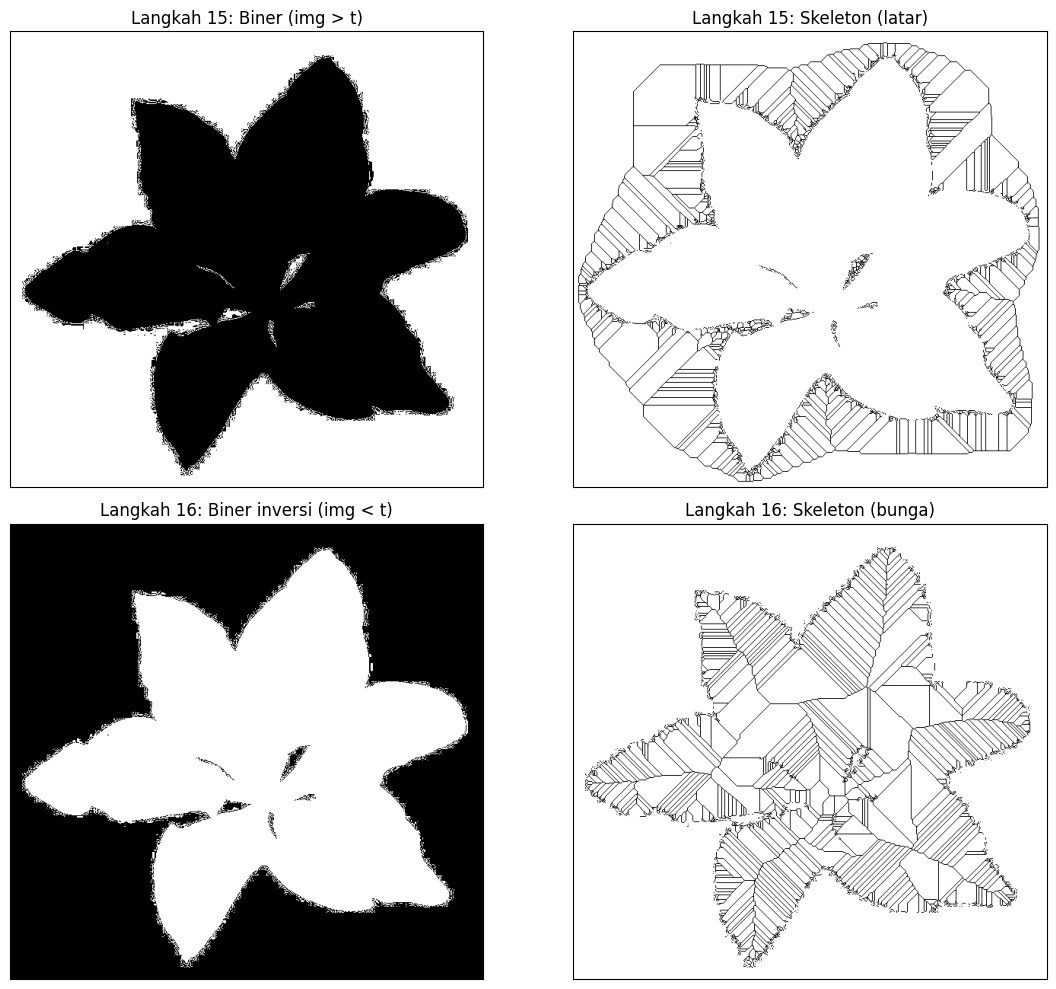

In [29]:
# Langkah 16 - Skeleton pada citra hasil inversi, dibandingkan dengan Langkah 15
from skimage import filters
from skimage.morphology import skeletonize

path = '/content/drive/MyDrive/PCVK2026/lily.jpg'   # sesuaikan
img = cv.imread(path, 0)
if img is None:
    raise FileNotFoundError(f'Gambar tidak terbaca, cek path: {path}')

t = filters.threshold_triangle(img)

# Langkah 15: latar yang True (tanpa inversi)
binary_15   = img > t
skeleton_15 = skeletonize(binary_15)

# Langkah 16: objek (bunga gelap) yang True (inversi)
binary_16   = img < t
skeleton_16 = skeletonize(binary_16)

print('threshold:', t)
print('Langkah 15 -> piksel True:', np.count_nonzero(binary_15), '| piksel skeleton:', np.count_nonzero(skeleton_15))
print('Langkah 16 -> piksel True:', np.count_nonzero(binary_16), '| piksel skeleton:', np.count_nonzero(skeleton_16))

plt.figure(figsize=(12, 10))

plt.subplot(221), plt.imshow(binary_15, cmap='gray')
plt.title('Langkah 15: Biner (img > t)'), plt.xticks([]), plt.yticks([])

plt.subplot(222), plt.imshow(skeleton_15, cmap='gray_r')
plt.title('Langkah 15: Skeleton (latar)'), plt.xticks([]), plt.yticks([])

plt.subplot(223), plt.imshow(binary_16, cmap='gray')
plt.title('Langkah 16: Biner inversi (img < t)'), plt.xticks([]), plt.yticks([])

plt.subplot(224), plt.imshow(skeleton_16, cmap='gray_r')
plt.title('Langkah 16: Skeleton (bunga)'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

Piksel biner     : 24736
Piksel skeleton  : 8998
Piksel thinning  : 8929


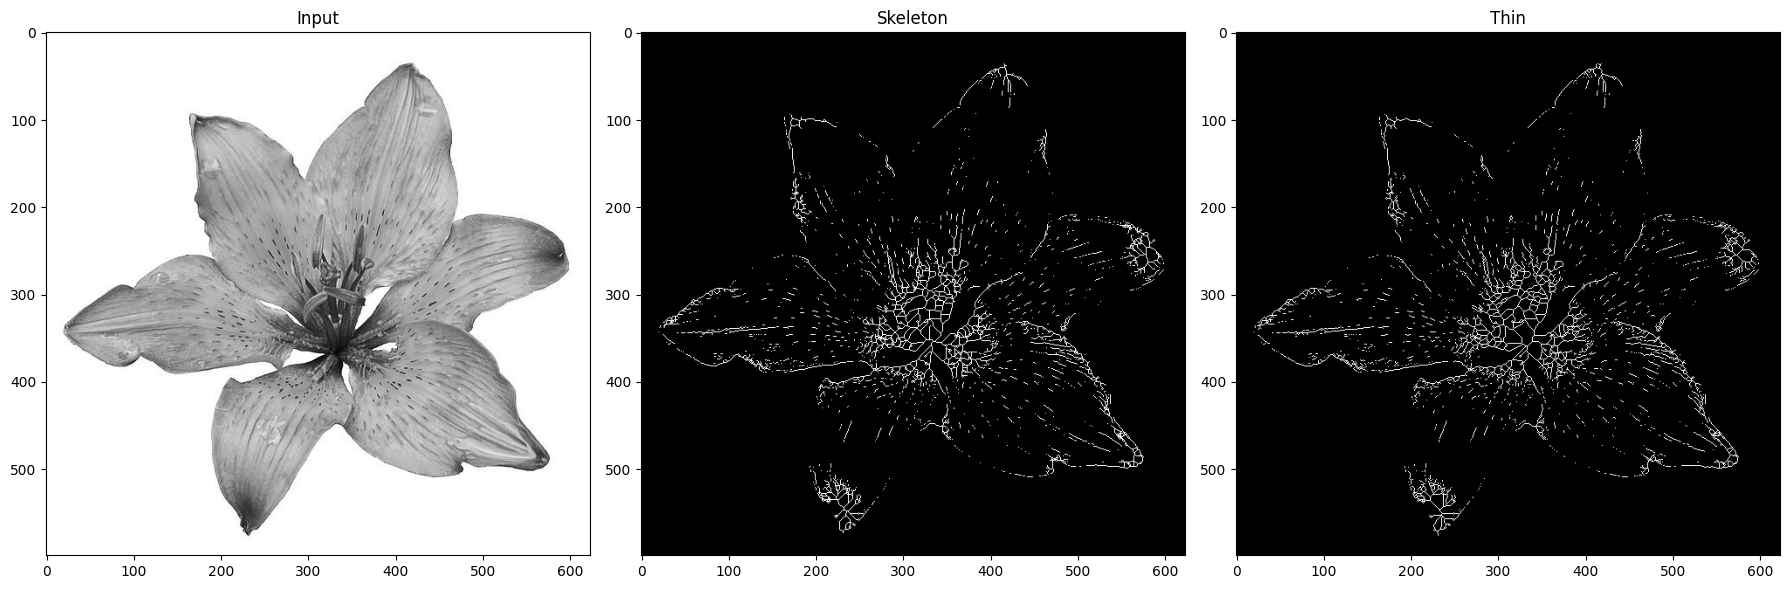

In [30]:
# Langkah 17 - Thinning dengan morphology.thin(), dibandingkan dengan skeleton
from skimage import morphology

path = '/content/drive/MyDrive/PCVK2026/lily.jpg'   # sesuaikan
img = cv.imread(path, 0)
if img is None:
    raise FileNotFoundError(f'Gambar tidak terbaca, cek path: {path}')

image = img / 255.0            # skala 0..1
image_binary = image < 0.5     # bagian gelap (bunga) menjadi True

out_skeletonize = morphology.skeletonize(image_binary)
out_thin        = morphology.thin(image_binary)

print('Piksel biner     :', np.count_nonzero(image_binary))
print('Piksel skeleton  :', np.count_nonzero(out_skeletonize))
print('Piksel thinning  :', np.count_nonzero(out_thin))

plt.figure(figsize=(18, 6))

plt.subplot(131), plt.imshow(image, cmap='gray')
plt.title('Input')

plt.subplot(132), plt.imshow(out_skeletonize, cmap='gray')
plt.title('Skeleton')

plt.subplot(133), plt.imshow(out_thin, cmap='gray')
plt.title('Thin')

plt.tight_layout()
plt.show()